# Quá khớp và cắt tỉa cây quyết định

*Bài 6, mục 6.1.4.* Nếu không giới hạn, cây tiếp tục chia cho tới khi mọi nút lá tinh khiết, tức là "học thuộc" cả nhiễu trong tập huấn luyện. Hai cách hạn chế:
- **Cắt tỉa trước** (pre-pruning): dừng phát triển cây sớm bằng các điều kiện dừng (`max_depth`, `min_samples_leaf`, …).
- **Cắt tỉa sau** (post-pruning): xây cây đầy đủ rồi cắt bớt các nhánh, ví dụ cắt tỉa theo độ phức tạp chi phí (`ccp_alpha`).

Dữ liệu: 500 điểm hai chiều hình hai nửa vầng trăng (`make_moons`) có nhiễu, hai lớp chồng lấn một phần.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X, y = make_moons(n_samples=500, noise=0.4, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=3)
print('Tập huấn luyện:', X_train.shape, ' tập kiểm tra:', X_test.shape)

Tập huấn luyện: (350, 2)  tập kiểm tra: (150, 2)


## 1. Cây đầy đủ (không giới hạn)

In [2]:
full_tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print('Độ sâu: %d, số nút lá: %d' % (full_tree.get_depth(), full_tree.get_n_leaves()))
print('Độ chính xác huấn luyện: %.3f' % full_tree.score(X_train, y_train))
print('Độ chính xác kiểm tra  : %.3f' % full_tree.score(X_test, y_test))

Độ sâu: 14, số nút lá: 70
Độ chính xác huấn luyện: 1.000
Độ chính xác kiểm tra  : 0.793


Độ chính xác huấn luyện bằng 1 nhưng trên tập kiểm tra thấp hơn rõ rệt: dấu hiệu **quá khớp**.

## 2. Ảnh hưởng của độ sâu tối đa

max_depth =  1: huấn luyện 0.791, kiểm tra 0.747
max_depth =  2: huấn luyện 0.866, kiểm tra 0.853
max_depth =  3: huấn luyện 0.871, kiểm tra 0.827
max_depth =  4: huấn luyện 0.891, kiểm tra 0.847
max_depth =  5: huấn luyện 0.906, kiểm tra 0.800
max_depth =  6: huấn luyện 0.931, kiểm tra 0.787
max_depth =  7: huấn luyện 0.951, kiểm tra 0.820
max_depth =  8: huấn luyện 0.963, kiểm tra 0.807
max_depth =  9: huấn luyện 0.974, kiểm tra 0.807
max_depth = 10: huấn luyện 0.983, kiểm tra 0.807
max_depth = 11: huấn luyện 0.989, kiểm tra 0.807
max_depth = 12: huấn luyện 0.997, kiểm tra 0.807
max_depth = 13: huấn luyện 0.997, kiểm tra 0.793
max_depth = 14: huấn luyện 1.000, kiểm tra 0.793
max_depth = 15: huấn luyện 1.000, kiểm tra 0.793


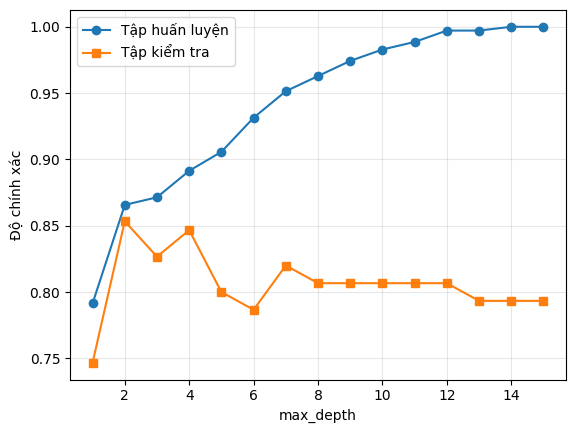

In [3]:
depths = range(1, 16)
train_scores, test_scores = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_scores.append(tree.score(X_train, y_train))
    test_scores.append(tree.score(X_test, y_test))
    print('max_depth = %2d: huấn luyện %.3f, kiểm tra %.3f' % (d, train_scores[-1], test_scores[-1]))

plt.plot(depths, train_scores, 'o-', label='Tập huấn luyện')
plt.plot(depths, test_scores, 's-', label='Tập kiểm tra')
plt.xlabel('max_depth'); plt.ylabel('Độ chính xác'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

Cây nông (`max_depth` = 1, 2) **chưa khớp**: sai nhiều trên cả hai tập. Khi tăng độ sâu, độ chính xác huấn luyện tăng dần tới 1, còn độ chính xác kiểm tra tăng rồi giảm.

## 3. Cắt tỉa trước: chọn siêu tham số bằng kiểm định chéo

Không dùng tập kiểm tra để chọn siêu tham số (Bài 2). `GridSearchCV` dùng kiểm định chéo 5 phần trên tập huấn luyện.

In [4]:
from sklearn.model_selection import GridSearchCV

param_grid = {'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
              'min_samples_leaf': [1, 5, 10, 20]}
search = GridSearchCV(DecisionTreeClassifier(random_state=0), param_grid, cv=5)
search.fit(X_train, y_train)
print('Siêu tham số tốt nhất:', search.best_params_)
print('Độ chính xác kiểm định chéo: %.3f' % search.best_score_)
best_tree = search.best_estimator_
print('Độ sâu: %d, số nút lá: %d' % (best_tree.get_depth(), best_tree.get_n_leaves()))
print('Độ chính xác kiểm tra: %.3f' % best_tree.score(X_test, y_test))

Siêu tham số tốt nhất: {'max_depth': 2, 'min_samples_leaf': 1}
Độ chính xác kiểm định chéo: 0.849
Độ sâu: 2, số nút lá: 4
Độ chính xác kiểm tra: 0.853


## 4. Cắt tỉa sau: cắt tỉa theo độ phức tạp chi phí

Với mỗi cây con $T$, CART định nghĩa chi phí
$$R_\alpha(T) = R(T) + \alpha\,|T|$$
trong đó $R(T)$ là tổng độ vẩn đục có trọng số của các nút lá, $|T|$ là số nút lá, $\alpha \ge 0$ là hệ số phạt. $\alpha$ càng lớn thì cây sau cắt tỉa càng nhỏ. `cost_complexity_pruning_path` trả về dãy các giá trị $\alpha$ mà tại đó một nhánh bị cắt.

Số giá trị alpha: 32


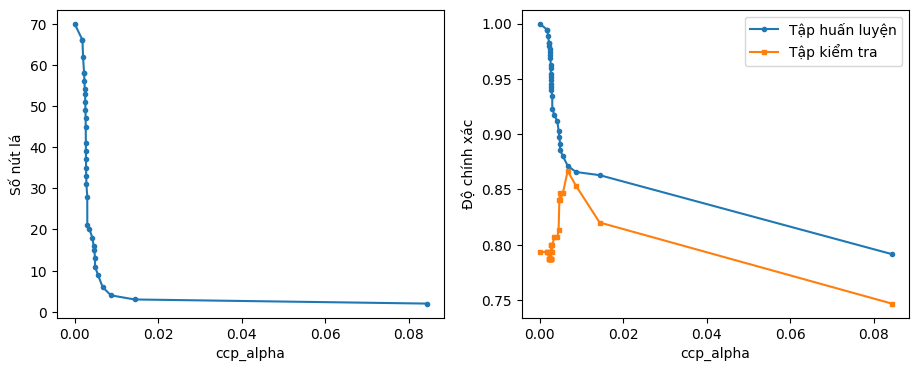

In [5]:
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]          # bỏ giá trị cuối (cây chỉ còn nút gốc)
print('Số giá trị alpha:', len(alphas))

n_leaves, train_scores, test_scores = [], [], []
for alpha in alphas:
    tree = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha).fit(X_train, y_train)
    n_leaves.append(tree.get_n_leaves())
    train_scores.append(tree.score(X_train, y_train))
    test_scores.append(tree.score(X_test, y_test))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(alphas, n_leaves, 'o-', ms=3)
axes[0].set_xlabel('ccp_alpha'); axes[0].set_ylabel('Số nút lá')
axes[1].plot(alphas, train_scores, 'o-', ms=3, label='Tập huấn luyện')
axes[1].plot(alphas, test_scores, 's-', ms=3, label='Tập kiểm tra')
axes[1].set_xlabel('ccp_alpha'); axes[1].set_ylabel('Độ chính xác'); axes[1].legend()
plt.show()

Chọn $\alpha$ bằng kiểm định chéo trên tập huấn luyện:

In [6]:
search = GridSearchCV(DecisionTreeClassifier(random_state=0), {'ccp_alpha': alphas}, cv=5)
search.fit(X_train, y_train)
pruned_tree = search.best_estimator_
print('ccp_alpha tốt nhất: %.4f' % search.best_params_['ccp_alpha'])
print('Số nút lá: %d -> %d' % (full_tree.get_n_leaves(), pruned_tree.get_n_leaves()))
print('Độ chính xác kiểm tra: %.3f -> %.3f' % (full_tree.score(X_test, y_test), pruned_tree.score(X_test, y_test)))

ccp_alpha tốt nhất: 0.0087
Số nút lá: 70 -> 4
Độ chính xác kiểm tra: 0.793 -> 0.853


## 5. So sánh ranh giới quyết định

Cây quyết định chia không gian đặc trưng thành các hình chữ nhật có cạnh song song với trục tọa độ. Cây đầy đủ tạo ra rất nhiều vùng nhỏ bao quanh từng điểm nhiễu; cây đã cắt tỉa có ranh giới đơn giản hơn.

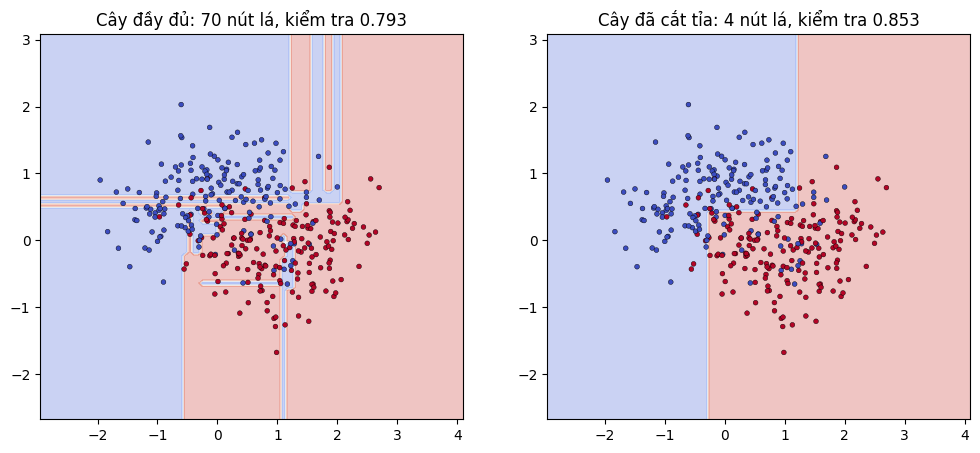

In [7]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, tree, title in [(axes[0], full_tree, 'Cây đầy đủ'), (axes[1], pruned_tree, 'Cây đã cắt tỉa')]:
    DecisionBoundaryDisplay.from_estimator(tree, X, response_method='predict', cmap='coolwarm', alpha=0.3, ax=ax)
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=12, edgecolors='k', linewidths=0.3)
    ax.set_title('%s: %d nút lá, kiểm tra %.3f' % (title, tree.get_n_leaves(), tree.score(X_test, y_test)))
plt.show()